In [18]:

!pip -q install numpy scipy matplotlib pandas reportlab h5py


stim shape: (3200,)
unique orientation codes: [1. 2. 3. 4. 5. 6. 7. 8.]
V1: <HDF5 dataset "b": shape (3200, 1280, 111), type "<f8">
0.0 deg: 400 trials
22.5 deg: 400 trials
45.0 deg: 400 trials
67.5 deg: 400 trials
90.0 deg: 400 trials
112.5 deg: 400 trials
135.0 deg: 400 trials
157.5 deg: 400 trials
counts (trials x neurons): (3200, 111)
mean_resp (orientations x neurons): (8, 111)


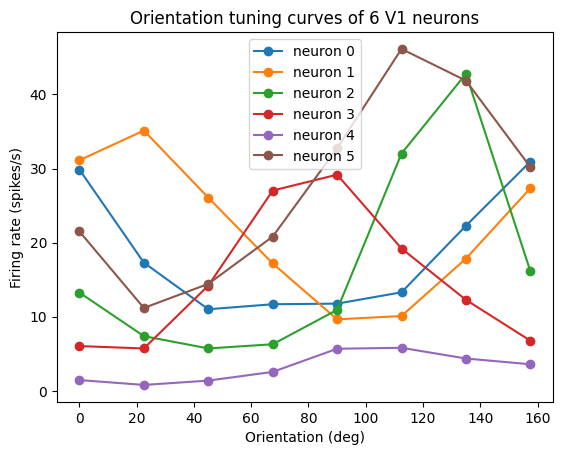

In [19]:
##Q1.
import h5py
import numpy as np
import matplotlib.pyplot as plt

MAT_FILE = "/content/107l003p143_spikes.mat"
STIM_S = 1.28     # stimulus duration in seconds (1280 ms)
f = h5py.File(MAT_FILE, "r")

# stimulus orientation on each trial (coded 1-8)
stim = f["stim"][()].flatten()
print("stim shape:", stim.shape)
print("unique orientation codes:", np.unique(stim))

# V1 spike array (accessed through a reference)
ref_v1 = f["spikes"][0, 0]
v1 = f[ref_v1]
print("V1:", v1)

# convert orientation codes to degrees: 8 orientations spanning 180 deg, 22.5 deg apart
ori = (stim - 1) * 22.5

# number of trials per orientation
for o in np.unique(ori):
    print(f"{o} deg: {np.sum(ori == o)} trials")

# spike count per trial, reading the file in blocks to save memory
n_trials, n_ms, n_neurons = v1.shape
counts = np.zeros((n_trials, n_neurons))

step = 100
for start in range(0, n_trials, step):
    block = v1[start:start + step]                  # 100 trials x 1280 ms x 111 neurons
    counts[start:start + step] = block.sum(axis=1)  # sum over milliseconds

print("counts (trials x neurons):", counts.shape)

# convert spike counts to firing rate (spikes per second)
rate = counts / STIM_S

orientations = np.unique(ori)   # the 8 orientations in degrees

# mean firing rate: rows = orientations, columns = neurons
mean_resp = np.zeros((len(orientations), n_neurons))
for k, o in enumerate(orientations):
    mean_resp[k] = rate[ori == o].mean(axis=0)

print("mean_resp (orientations x neurons):", mean_resp.shape)

# tuning curves of the first 6 neurons
for n in range(6):
    plt.plot(orientations, mean_resp[:, n], marker="o", label=f"neuron {n}")

plt.xlabel("Orientation (deg)")
plt.ylabel("Firing rate (spikes/s)")
plt.legend()
plt.title("Orientation tuning curves of 6 V1 neurons")
plt.show()



In [20]:
##Ques 2

from numpy.polynomial import Polynomial
import numpy as np
import matplotlib.pyplot as plt

# Experimental data for neuron 0
x = orientations.astype(float)
y = mean_resp[:, 0]

# Polynomial degrees required by the assignment
degrees = [1, 3, 4, 7]

models = {}
mse_values = {}

# Fit each model and calculate MSE
for degree in degrees:
    model = Polynomial.fit(x, y, deg=degree)
    predictions = model(x)

    mse = np.mean((y - predictions) ** 2)

    models[degree] = model
    mse_values[degree] = mse

    print(f"Degree {degree} polynomial")
    print(f"MSE = {mse:.6f}\n")

# Display results in increasing degree order
print("SUMMARY OF MSE VALUES")
for degree in degrees:
    print(f"Degree {degree}: {mse_values[degree]:.6f}")


Degree 1 polynomial
MSE = 58.149033

Degree 3 polynomial
MSE = 1.351405

Degree 4 polynomial
MSE = 0.860375

Degree 7 polynomial
MSE = 0.000000

SUMMARY OF MSE VALUES
Degree 1: 58.149033
Degree 3: 1.351405
Degree 4: 0.860375
Degree 7: 0.000000


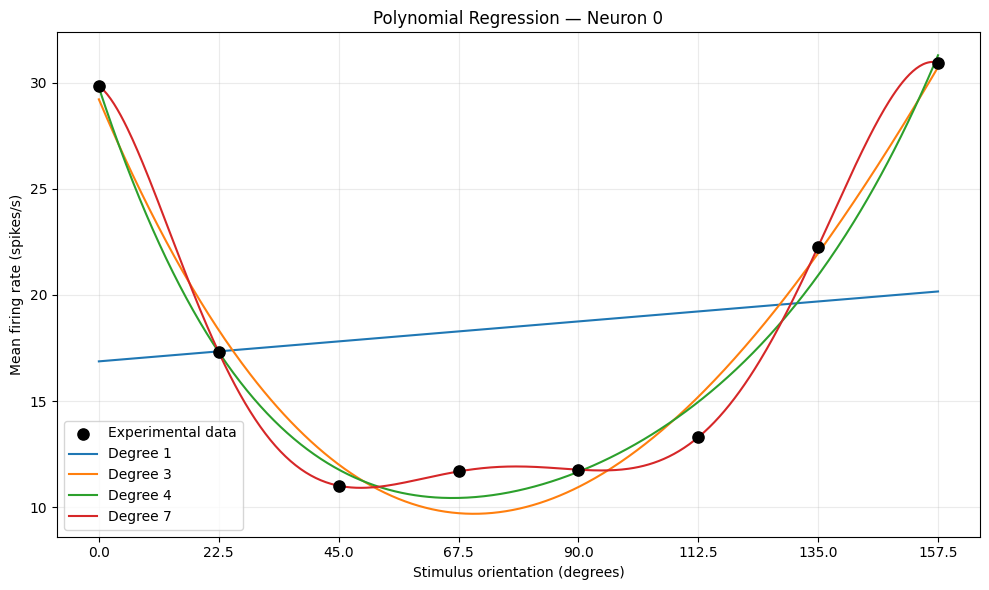

In [21]:

# Plot experimental data and polynomial fits

x_smooth = np.linspace(x.min(), x.max(), 500)

plt.figure(figsize=(10, 6))

plt.scatter(
    x, y,
    color="black",
    s=65,
    label="Experimental data",
    zorder=5
)

for degree in degrees:
    plt.plot(
        x_smooth,
        models[degree](x_smooth),
        label=f"Degree {degree}"
    )

plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (spikes/s)")
plt.title("Polynomial Regression — Neuron 0")
plt.xticks(x)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [22]:
##Ques 3
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

def gaussian_tuning(theta, B, A, mu, sigma):
    return B + A * np.exp(
        -((theta - mu) ** 2) / (2 * sigma ** 2)
    )

# Use the existing experimental data for neuron 0
x = orientations.astype(float)
y = mean_resp[:, 0]

best_params = None
best_mse = np.inf

# Try multiple starting values
for mu0 in [0, 22.5, 45, 67.5, 90, 112.5, 135, 157.5]:
    for sigma0 in [20, 40, 70, 100]:
        try:
            params, _ = curve_fit(
                gaussian_tuning,
                x,
                y,
                p0=[np.min(y), np.max(y) - np.min(y), mu0, sigma0],
                bounds=(
                    [0, 0, 0, 5],
                    [100, 100, 180, 180]
                ),
                maxfev=30000
            )

            predictions = gaussian_tuning(x, *params)
            mse = np.mean((y - predictions) ** 2)

            if mse < best_mse:
                best_mse = mse
                best_params = params

        except RuntimeError:
            continue

B_fit, A_fit, mu_fit, sigma_fit = best_params

print(f"Baseline B: {B_fit:.4f}")
print(f"Amplitude A: {A_fit:.4f}")
print(f"Preferred orientation mu: {mu_fit:.4f} degrees")
print(f"Tuning width sigma: {sigma_fit:.4f} degrees")
print(f"Gaussian MSE: {best_mse:.6f}")



Baseline B: 15.8200
Amplitude A: 48.5212
Preferred orientation mu: 147.7817 degrees
Tuning width sigma: 6.3656 degrees
Gaussian MSE: 32.762409


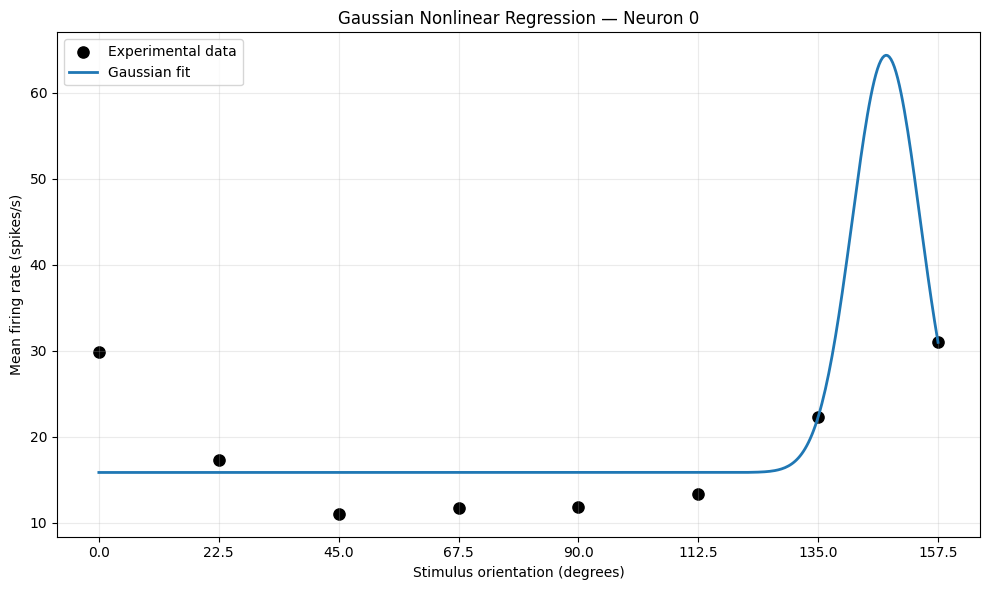

In [23]:
# Plot the fit
x_smooth = np.linspace(x.min(), x.max(), 500)

plt.figure(figsize=(10, 6))
plt.scatter(x, y, color="black", s=65, label="Experimental data")
plt.plot(
    x_smooth,
    gaussian_tuning(x_smooth, *best_params),
    label="Gaussian fit",
    linewidth=2
)
plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (spikes/s)")
plt.title("Gaussian Nonlinear Regression — Neuron 0")
plt.xticks(x)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [24]:
print(f"B = {B_fit:.4f}")
print(f"A = {A_fit:.4f}")
print(f"mu = {mu_fit:.4f} degrees")
print(f"sigma = {sigma_fit:.4f} degrees")
print(f"Gaussian MSE = {best_mse:.6f}")

B = 15.8200
A = 48.5212
mu = 147.7817 degrees
sigma = 6.3656 degrees
Gaussian MSE = 32.762409


In [25]:

# Compare Gaussian and polynomial models

print("MSE comparison — Neuron 0")
for degree in [1, 3, 4, 7]:
    print(f"Polynomial degree {degree}: {mse_values[degree]:.6f}")

print(f"Gaussian: {best_mse:.6f}")


MSE comparison — Neuron 0
Polynomial degree 1: 58.149033
Polynomial degree 3: 1.351405
Polynomial degree 4: 0.860375
Polynomial degree 7: 0.000000
Gaussian: 32.762409


In [26]:
##Ques4:


from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

# Equivalent, numerically stable von Mises parameterization
def von_mises_tuning(theta, B, A, mu, kappa):
    angle_diff = np.deg2rad(theta - mu)
    return B + A * np.exp(
        kappa * (np.cos(2 * angle_diff) - 1)
    )

# Experimental data for neuron 0
x = orientations.astype(float)
y = mean_resp[:, 0]

best_vm_params = None
best_vm_mse = np.inf

# Try multiple initial preferred orientations and concentrations
for mu0 in [0, 22.5, 45, 90, 135, 157.5, 180]:
    for kappa0 in [0.1, 0.5, 1, 2, 5]:
        try:
            params, _ = curve_fit(
                von_mises_tuning,
                x,
                y,
                p0=[
                    np.min(y),
                    np.max(y) - np.min(y),
                    mu0,
                    kappa0
                ],
                bounds=(
                    [0, 0, 0, 0.001],
                    [100, 100, 180, 100]
                ),
                maxfev=50000
            )

            predictions = von_mises_tuning(x, *params)
            mse = np.mean((y - predictions) ** 2)

            if mse < best_vm_mse:
                best_vm_mse = mse
                best_vm_params = params

        except (RuntimeError, ValueError):
            continue

B_vm, A_vm, mu_vm, kappa_vm = best_vm_params

print(f"Baseline B: {B_vm:.4f}")
print(f"Amplitude A: {A_vm:.4f}")
print(f"Preferred orientation mu: {mu_vm:.4f} degrees")
print(f"Concentration kappa: {kappa_vm:.4f}")
print(f"Von Mises MSE: {best_vm_mse:.6f}")




Baseline B: 9.2493
Amplitude A: 23.6444
Preferred orientation mu: 164.6936 degrees
Concentration kappa: 1.3469
Von Mises MSE: 0.720111


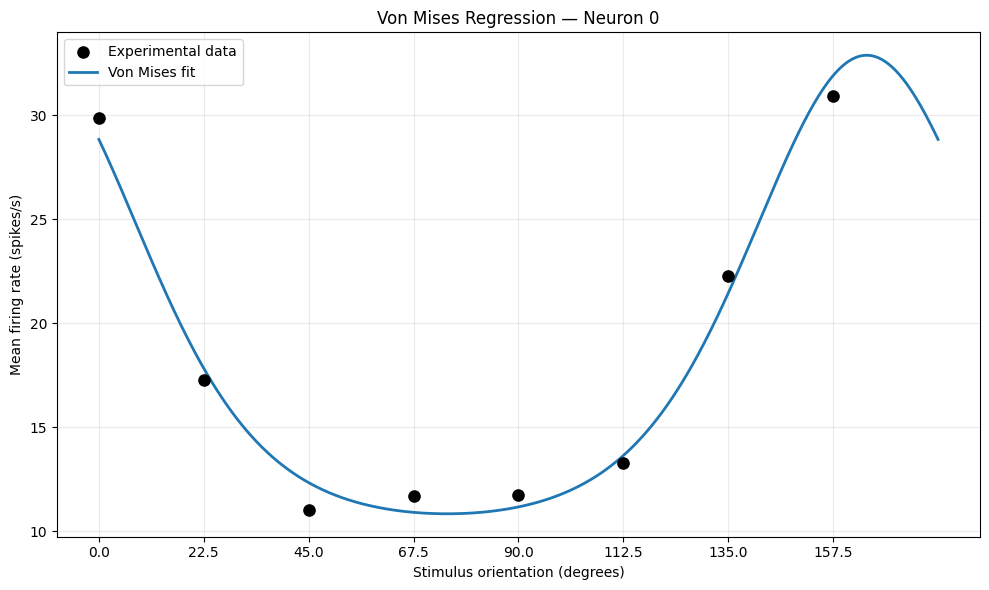

In [27]:
# Plot the fitted circular model
x_smooth = np.linspace(0, 180, 500)

plt.figure(figsize=(10, 6))
plt.scatter(
    x, y,
    color="black",
    s=65,
    label="Experimental data",
    zorder=5
)
plt.plot(
    x_smooth,
    von_mises_tuning(x_smooth, *best_vm_params),
    label="Von Mises fit",
    linewidth=2
)
plt.xlabel("Stimulus orientation (degrees)")
plt.ylabel("Mean firing rate (spikes/s)")
plt.title("Von Mises Regression — Neuron 0")
plt.xticks(x)
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [28]:

print("MSE comparison — Neuron 0")
print(f"Linear polynomial:      {mse_values[1]:.6f}")
print(f"Third-degree polynomial: {mse_values[3]:.6f}")
print(f"Fourth-degree polynomial:{mse_values[4]:.6f}")
print(f"Seventh-degree polynomial:{mse_values[7]:.6f}")
print(f"Gaussian:                {best_mse:.6f}")
print(f"Von Mises:               {best_vm_mse:.6f}")


MSE comparison — Neuron 0
Linear polynomial:      58.149033
Third-degree polynomial: 1.351405
Fourth-degree polynomial:0.860375
Seventh-degree polynomial:0.000000
Gaussian:                32.762409
Von Mises:               0.720111



Neuron 0:   model / MSE (all trials) / test MSE
  4th-order polynomial      0.860    1.304
  Gaussian                 32.762   34.527
  von Mises                 0.720    1.178

Neuron 4:   model / MSE (all trials) / test MSE
  4th-order polynomial      0.233    0.250
  Gaussian                  0.225    0.236
  von Mises                 0.241    0.244

Neuron 9:   model / MSE (all trials) / test MSE
  4th-order polynomial      0.339    0.497
  Gaussian                  0.103    0.219
  von Mises                 0.115    0.230


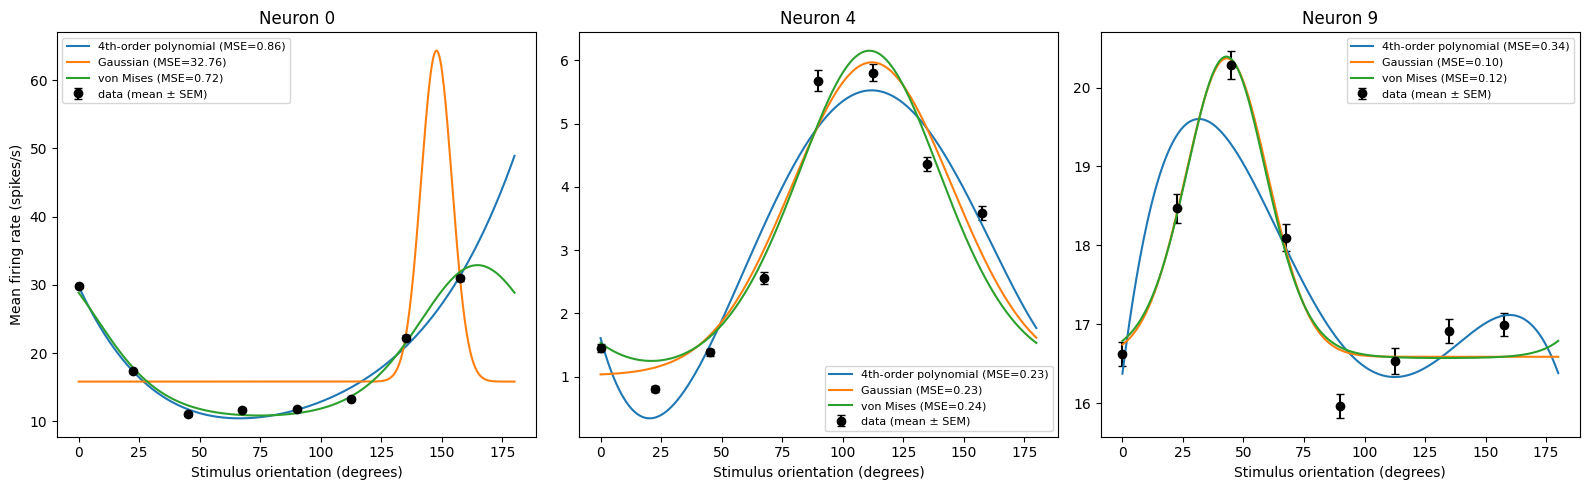

In [29]:
##Ques 5
neurons = [0, 4, 9]                      # main neuron + two noisier neurons
x = orientations.astype(float)
x_smooth = np.linspace(0, 180, 500)

def fit(model, y):
    """Fit one model to 8 mean responses and return the fitted curve as a function."""
    if model == "4th-order polynomial":
        return Polynomial.fit(x, y, deg=4)
    func = gaussian_tuning if model == "Gaussian" else von_mises_tuning
    p0 = [y.min(), np.ptp(y), x[np.argmax(y)], 30 if model == "Gaussian" else 1]
    upper = [100, 100, 180, 180 if model == "Gaussian" else 100]
    p, _ = curve_fit(func, x, y, p0=p0, bounds=([0, 0, 0, 0.001], upper), maxfev=50000)
    return lambda t: func(t, *p)

# train = even trials, test = odd trials of each orientation
train = np.array([rate[ori == o][::2].mean(axis=0) for o in orientations])
test = np.array([rate[ori == o][1::2].mean(axis=0) for o in orientations])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, n in zip(axes, neurons):
    y = mean_resp[:, n]
    sem = [rate[ori == o, n].std() / np.sqrt(np.sum(ori == o)) for o in orientations]
    ax.errorbar(x, y, yerr=sem, fmt="ko", capsize=3, label="data (mean ± SEM)")
    print(f"\nNeuron {n}:   model / MSE (all trials) / test MSE")
    for model in ["4th-order polynomial", "Gaussian", "von Mises"]:
        f = fit(model, y)
        mse = np.mean((y - f(x)) ** 2)
        test_mse = np.mean((test[:, n] - fit(model, train[:, n])(x)) ** 2)
        print(f"  {model:22s} {mse:8.3f} {test_mse:8.3f}")
        ax.plot(x_smooth, f(x_smooth), label=f"{model} (MSE={mse:.2f})")
    ax.set_title(f"Neuron {n}")
    ax.set_xlabel("Stimulus orientation (degrees)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Mean firing rate (spikes/s)")
plt.tight_layout()
plt.show()